In [30]:
import numpy as np
import matplotlib.pyplot as plt
from os import listdir
from os.path import isfile, join
plt.style.use('seaborn')

In [31]:
# Set variables
BUILD_PATH = "../build"
PROBLEM_PATH = "../problems/pure_int_bench"
LP = "LP Diff"
CUTOFF = "Cutoff Diff"

In [32]:
# Get problem names
problem_set = [f for f in listdir(PROBLEM_PATH)
                 if isfile(join(PROBLEM_PATH, f)) and ":Zone.Identifier" not in f]

In [33]:
# Get folder with results
folder = join(BUILD_PATH, input())

In [34]:
# parser function
def parser(file_path : str) -> dict:
    result = {}
    # open file
    with open(file_path) as my_file:
        for line in my_file:
            # check solution
            if "No incumbent" in line or not line.strip():
                continue
            # clear line
            line = line.strip()
            # get position
            first_quote = line.find('"')
            second_quote = line.find('"', first_quote + 1)
            second_equal = line.find("=", line.find("=") + 1)
            last_equal = line.rfind("=")
            semicolon = line.find(";")
            # get values
            cut_type = line[first_quote + 1 : second_quote]
            lp_diff = abs(float(line[second_equal + 2 : semicolon]))
            cutoff_diff = abs(float(line[last_equal + 2 : ]))
            # fill the dictionary with new values
            result[cut_type] = {}
            result[cut_type][LP] = lp_diff
            result[cut_type][CUTOFF] = cutoff_diff
    return result


In [35]:
# Calculate absolute lists
def calc_absolute(values : dict, diff : str) -> tuple:
    types = filter(lambda x : x in ["my", "my+all", "none"] or values[x][diff] != values["none"][diff], values)
    X = list(types)
    y = [values[x][diff] for x in X]
    colors = ["blue"] * len(X)
    for mode in ["my", "my+all"]:
        if mode in X:
            colors[X.index(mode)] = "red"
    return X, y, colors

In [36]:
# Calculate percent lists
def calc_percent(values : dict, diff : str) -> tuple:
    pairs = [(x, values["none"][diff] - values[x][diff]) for x in values]
    pairs = list(filter(lambda x: x[1] != 0, pairs))
    not_my_pairs = list(filter(lambda x: x[0] not in ["my", "my+all"], pairs))
    if not_my_pairs:
        max_type, max_value = max(not_my_pairs, key=lambda x: x[1])
        pairs = list(map(lambda x: (x[0], abs((max_value - x[1]) / max_value) * 100 + 100) if x[1] > max_value
                             else  (x[0],-abs((max_value - x[1]) / max_value) * 100 + 100), pairs))
        y = [x[1] for x in pairs]
        X = [x[0] if x[0] != max_type else "MAX\n" + x[0] for x in pairs]
        colors = ["blue"] * len(X)
        if "MAX\n" + max_type in X:
            colors[X.index("MAX\n" + max_type)] = "green"
        for mode in ["my", "my+all"]:
            if mode in X:
                colors[X.index(mode)] = "red"
        return X, y, colors
    else:
        return None, None, None

In [37]:
# To graph data values
def graph(values : dict, problem : str) -> None:
    if not values:
        return
    # Get absolute values
    X_lp_abs, y_lp_abs, lp_abs_color = calc_absolute(values, LP)
    X_cut_abs, y_cut_abs, cut_abs_color = calc_absolute(values, CUTOFF)
    # Get percent values
    X_lp_per, y_lp_per, lp_per_color = calc_percent(values, LP)
    X_cut_per, y_cut_per, cut_per_color = calc_percent(values, CUTOFF)
    # Set subplots
    fig, axes = plt.subplots(2, 2, figsize=(35, 25))
    fig.suptitle(problem, fontsize=40)
    axes[0][0].tick_params(axis="x", labelsize=15, labelrotation=75)
    axes[0][1].tick_params(axis="x", labelsize=15, labelrotation=75)
    axes[1][0].tick_params(axis="x", labelsize=15, labelrotation=75)
    axes[1][1].tick_params(axis="x", labelsize=15, labelrotation=75)
    axes[0][0].tick_params(axis="y", labelsize=15)
    axes[0][1].tick_params(axis="y", labelsize=15)
    axes[1][0].tick_params(axis="y", labelsize=15)
    axes[1][1].tick_params(axis="y", labelsize=15)
    axes[0][0].set_title("Absolute " + LP, fontsize=20)
    axes[0][1].set_title("Absolute " + CUTOFF, fontsize=20)
    axes[1][0].set_title("Percent " + LP, fontsize=20)
    axes[1][1].set_title("Percent " + CUTOFF, fontsize=20)
    # Plot data
    axes[0][0].bar(x=X_lp_abs, height=y_lp_abs, log=False, color=lp_abs_color)
    axes[0][1].bar(x=X_cut_abs, height=y_cut_abs, log=False, color=cut_abs_color)
    if not X_lp_per:
        axes[1][0].remove()
    else:
        bottom = np.floor(min(min(y_lp_per), 0))
        top = np.ceil(max(y_lp_per))
        step = (top - bottom)/15
        top += step
        axes[1][0].set_yticks(np.arange(bottom, top, step=step))
        axes[1][0].bar(x=X_lp_per, height=y_lp_per, color=lp_per_color)
    if not X_cut_per:
        axes[1][1].remove()
    else:
        bottom = np.floor(min(min(y_cut_per), 0))
        top = np.ceil(max(max(y_cut_per), 0))
        step = (top - bottom) / 15
        top += step
        axes[1][1].set_yticks(np.arange(bottom, top, step=step))
        axes[1][1].bar(x=X_cut_per, height=y_cut_per, color=cut_per_color)

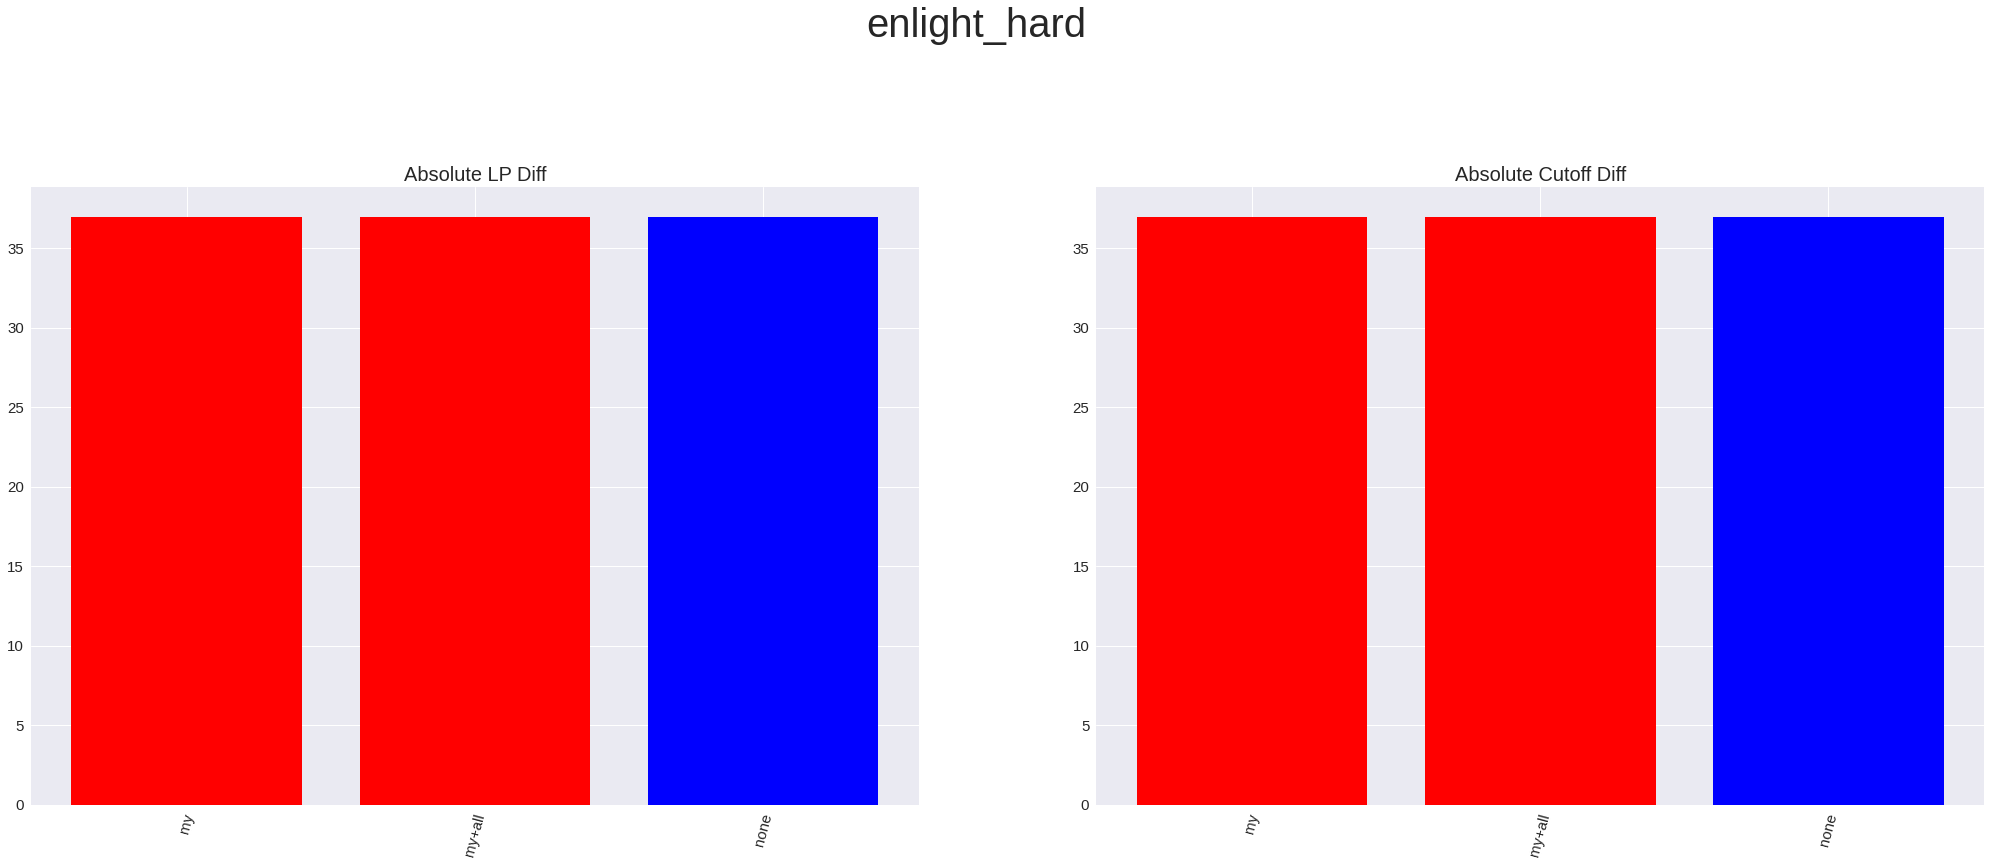

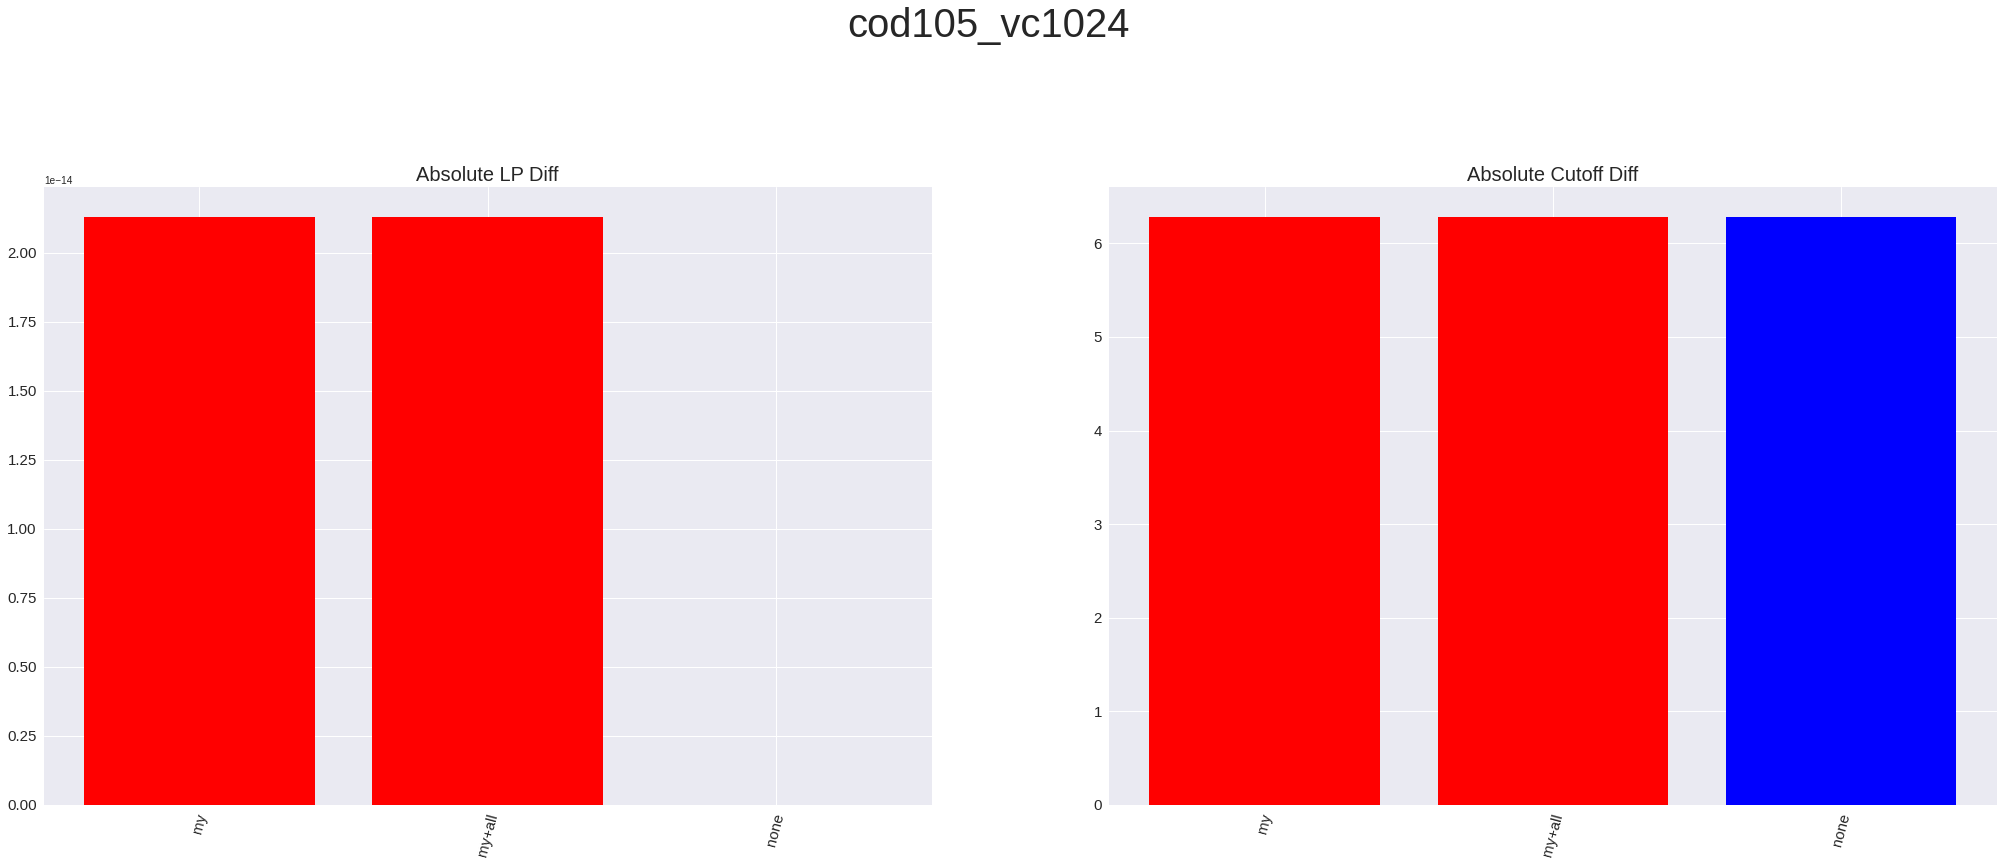

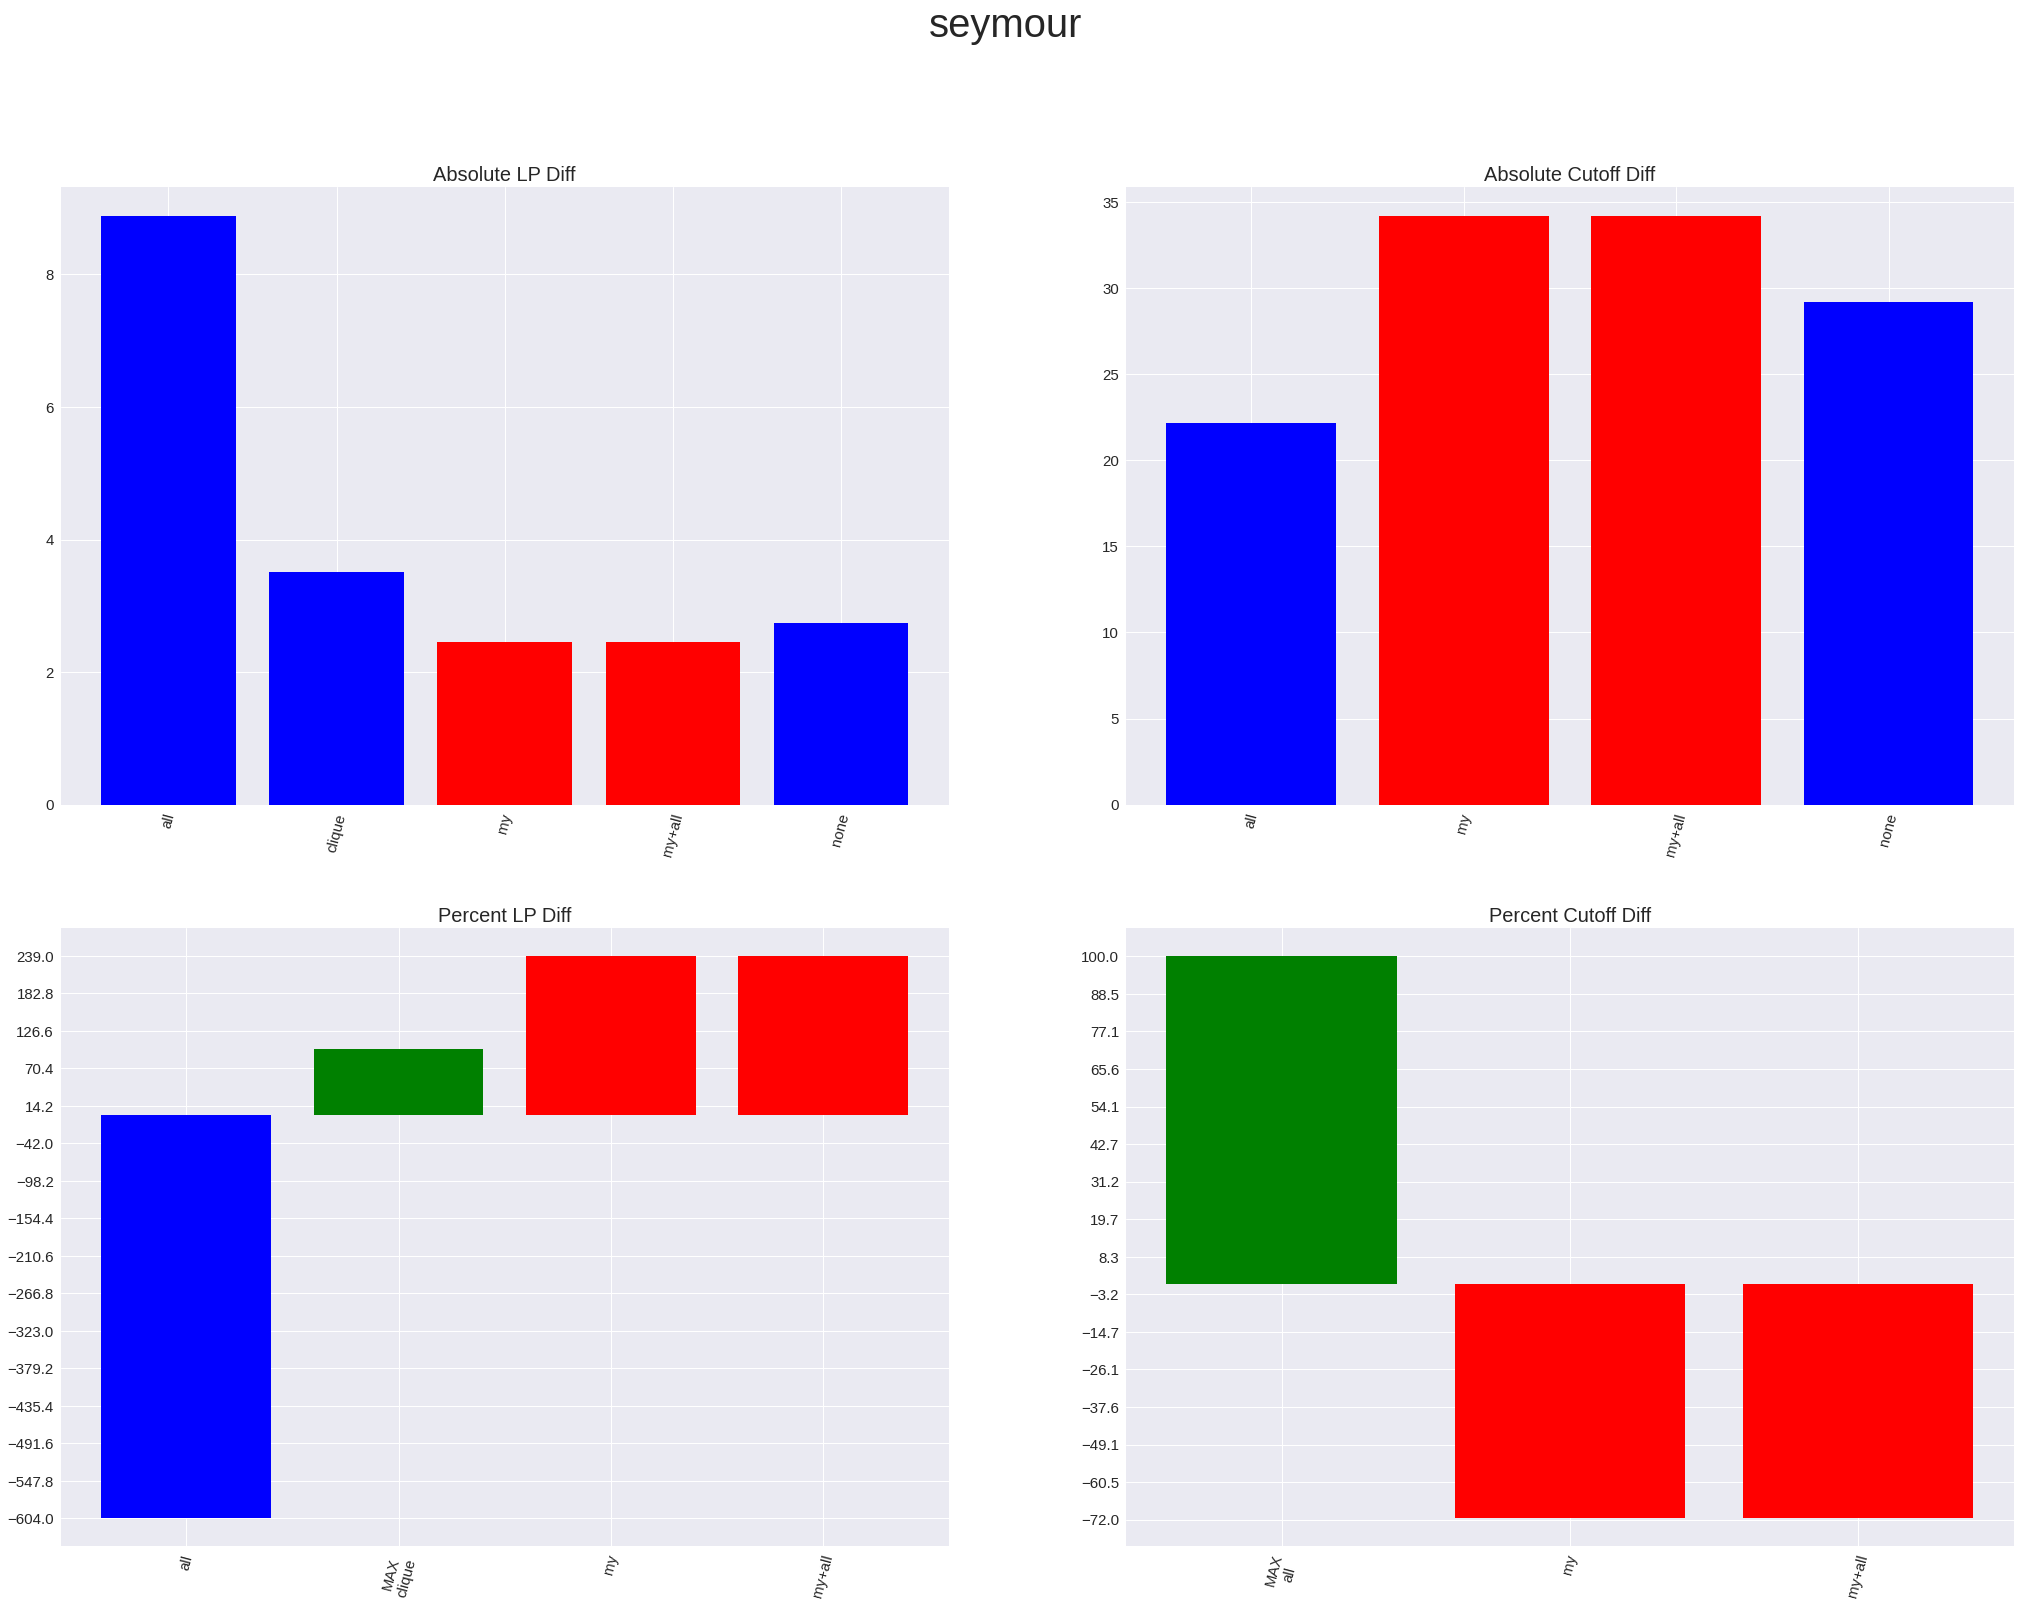

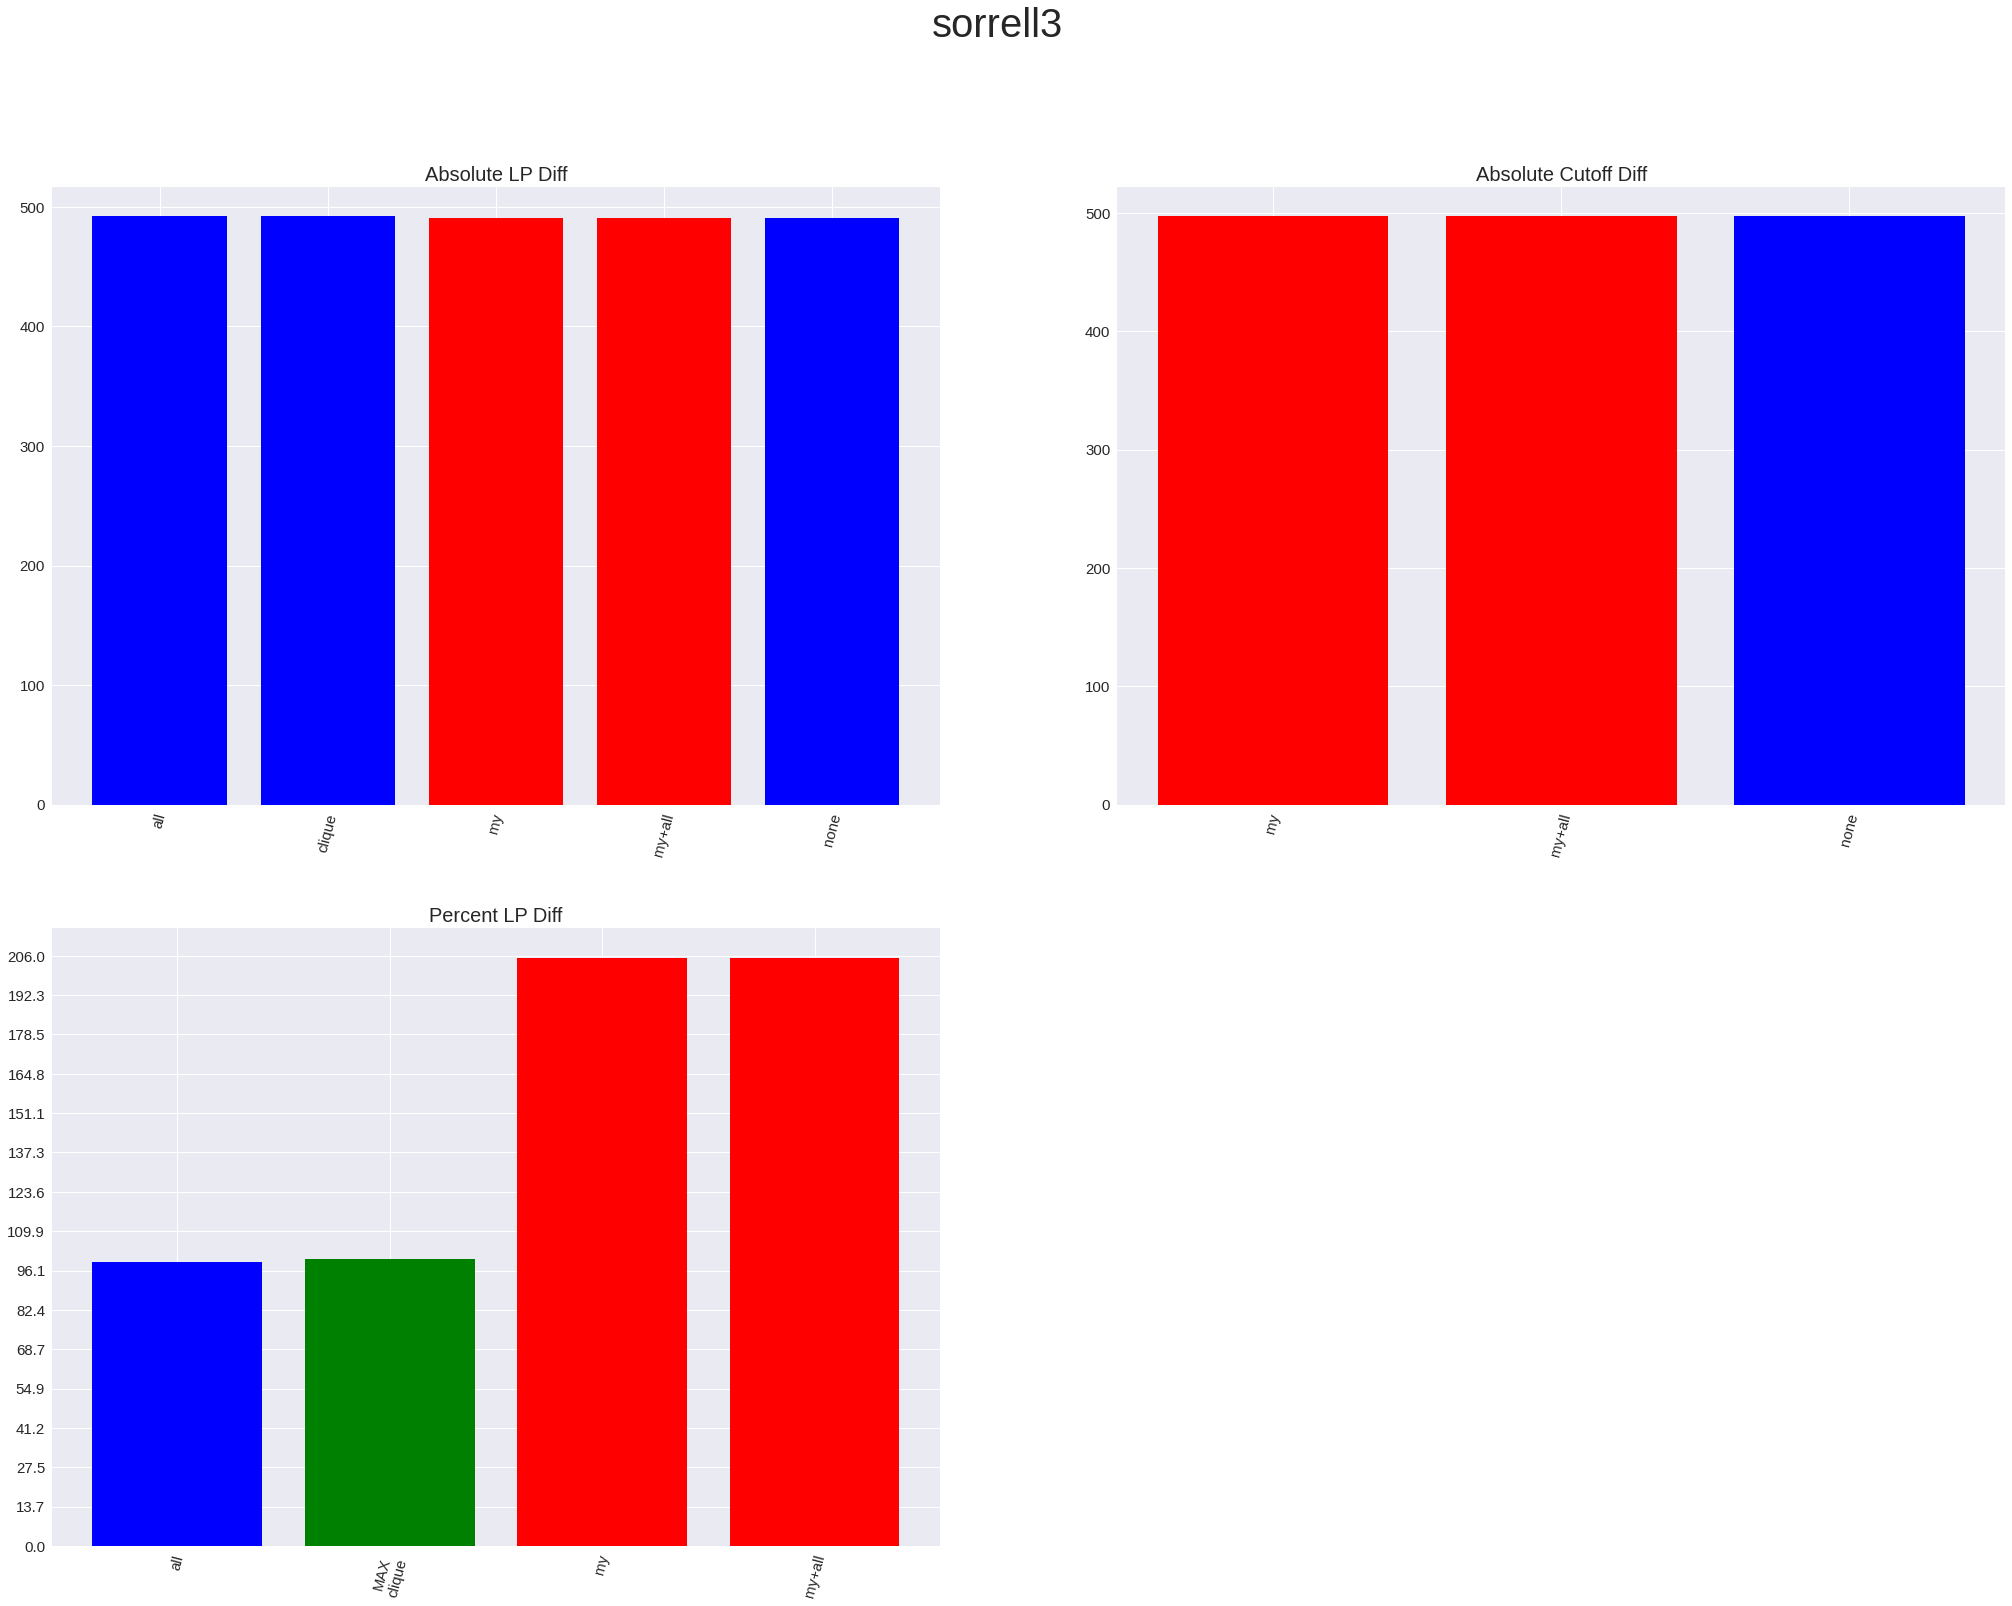

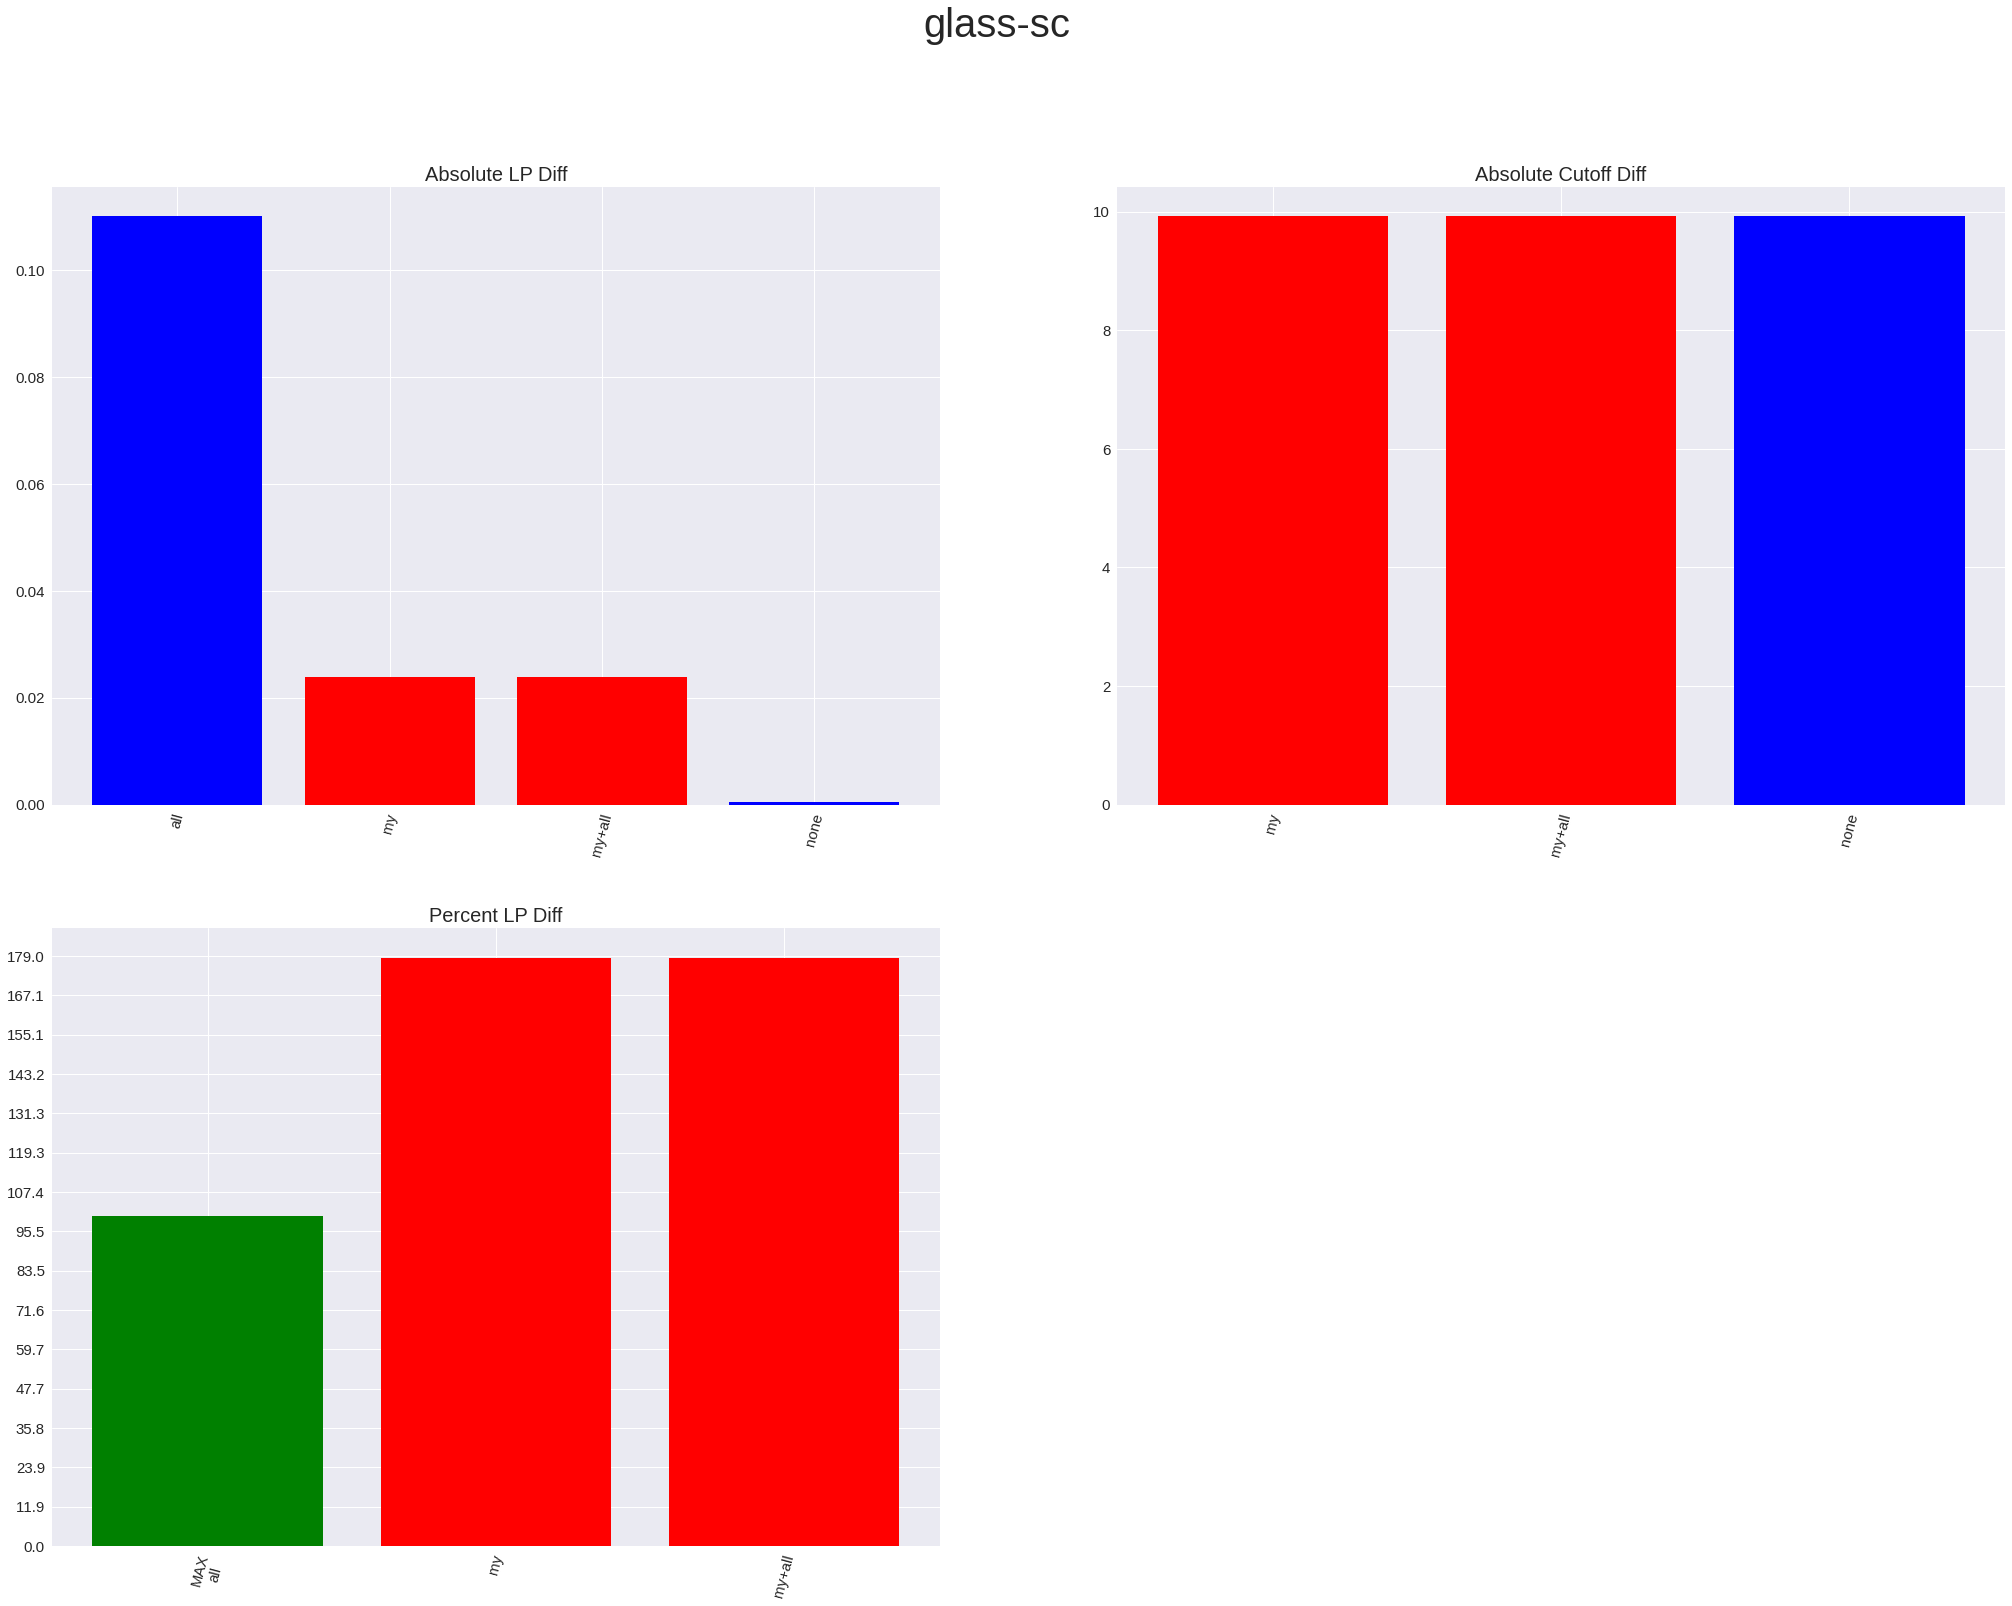

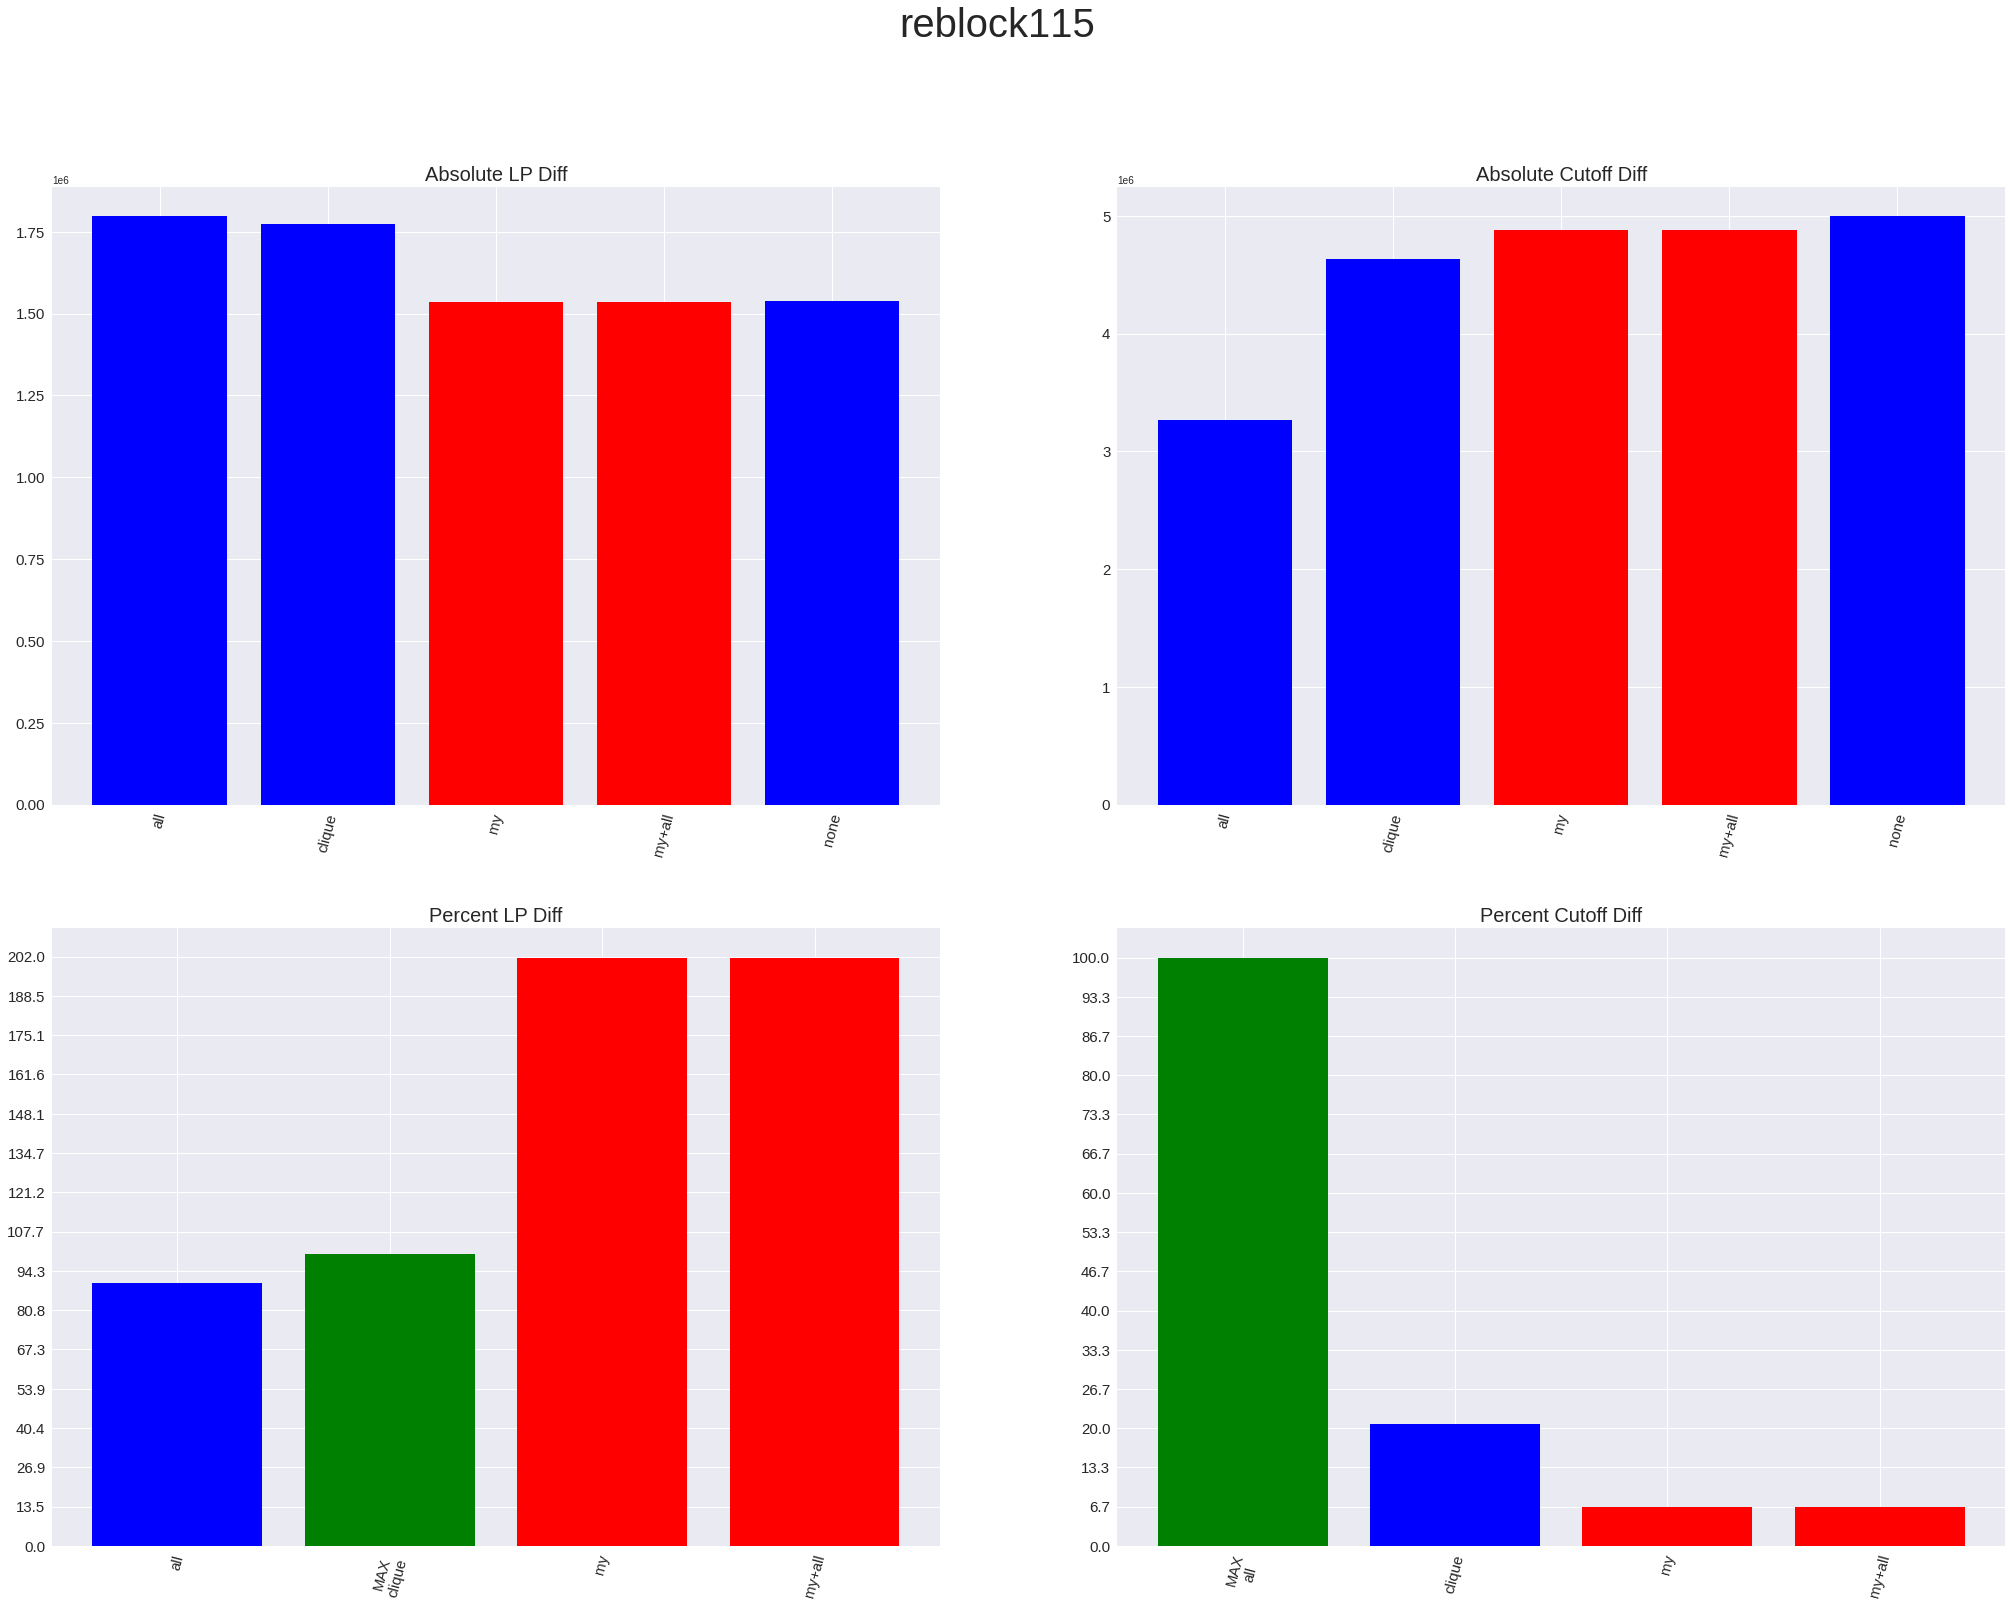

In [38]:
# main program
for p in problem_set:
    problem_path = join(folder, p + "_results.txt")
    if isfile(problem_path): # Check if a file exists
        graph(values=parser(problem_path), problem=p[ : p.find(".")])